### Wachstum: exponentiell, beschränkt, logistisch, Differentialgleichungen - Übungen

In diesem Notebook geht es um **Wachstumsmodelle**: exponentielles Wachstum und exponentielle Abnahme, beschränktes Wachstum
und (als Zusatz) logistisches Wachstum. Du bestimmst die Parameter eines Modells aus Messwerten, berechnest Verdopplungs- und Halbwertszeiten
und untersuchst, wie Bestand und Änderungsrate zusammenhängen. Im Leistungsfach löst du die zugehörigen **Differentialgleichungen** mit `dsolve()`.

Die Zeitvariable heißt `t`. Kommazahlen in Modellen schreibst du als `Rational`, damit sympy genau rechnet.

Vorausgesetzt werden die Notebooks *Ableitungsregeln* und *Integrale*.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Unter den meisten Aufgaben steht das **erwartete Ergebnis**.

**Brüche und Kommazahlen:** Python rechnet `1/6` oder `0.5` sofort als Kommazahl, bevor sympy die Zahl sieht.
Die erwarteten Ausgaben sind aber mit exakten Brüchen berechnet. Schreibe solche Zahlen deshalb mit `Rational`: `Rational(1, 6)` für 1/6,
`Rational('0.5')` für 0,5. Bei einer Division ganzer Zahlen genügt es, eine davon mit `Integer` zu schreiben: `Integer(1) / 6`.
Aufgaben, bei denen das nötig ist, haben einen entsprechenden Hinweis.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### sympy laden

**Führe diese Zelle zuerst aus** (und nach jedem Neustart des Kernels wieder). Sie lädt sympy und matplotlib, schaltet die Formel-Ausgabe ein
und legt die reellen Variablen `t` und `k` an.

**Achtung:** Verwende nicht `S` als eigenen Variablennamen, `S` gehört zu sympy (z. B. `S.Reals`). Die Schranke heißt in den Programmen deshalb `G`.

In [ ]:
from sympy import *
init_printing()
import matplotlib.pyplot as plt
t = symbols('t', real=True)
k = symbols('k', real=True)

## 1. Exponentielles Wachstum und Abnahme

#### f(t) = f(0) · e^(kt)

Bei **exponentiellem Wachstum** wächst der Bestand in gleichen Zeitschritten um denselben **Faktor**. Mit der e-Funktion schreibt man
f(t) = f(0) · e^(kt) mit der **Wachstumskonstante** k: k > 0 Wachstum, k < 0 Abnahme.

Ist der Wachstumsfaktor pro Zeitschritt a (z. B. a = 1,05 bei 5 % Zunahme), dann ist k = ln(a), denn aᵗ = e^(t·ln a).

**Verdopplungszeit** (k > 0): T = ln(2)/k. **Halbwertszeit** (k < 0): T = ln(2)/|k|.

Gleichungen mit e-Funktionen löst du am besten mit `solveset(..., S.Reals)`, das liefert einfachere Logarithmen als `solve`.
Das einzige Element einer Lösungsmenge `l` bekommst du mit `list(l)[0]`.

In [ ]:
f = 500 * exp(log(Rational(105, 100)) * t)
display(f)
display(N(f.subs(t, 10), 5))
l = solveset(Eq(f, 1000), t, S.Reals)
display(l)
N(list(l)[0], 4)

#### Aufgabe 1.1

Ein Kapital von 2000 € wird mit 3 % pro Jahr verzinst. Gib das Modell f(t) = 2000 · e^(kt) mit k = ln(1,03) aus und den Wert nach 10 Jahren (auf Cent gerundet: `round(N(...), 2)`).

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle 2000 e^{t \log{\left(\frac{103}{100} \right)}}$

$\displaystyle 2687.83$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = 2000 * exp(log(Rational(103, 100)) * t)
display(f)
round(N(f.subs(t, 10)), 2)
```

</details>

#### Aufgabe 1.2

Nach wie vielen Jahren hat sich das Kapital aus der vorigen Aufgabe verdoppelt? Genau und mit 4 Ziffern.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \left\{\frac{\log{\left(2 \right)}}{\log{\left(\frac{103}{100} \right)}}\right\}$

$\displaystyle 23.45$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = solveset(Eq(2000 * exp(log(Rational(103, 100)) * t), 4000), t, S.Reals)
display(l)
N(list(l)[0], 4)
```

</details>

#### Aufgabe 1.3

Berechne die Verdopplungszeit für k = 0,1 mit T = ln(2)/k genau und mit 4 Ziffern.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle 10 \log{\left(2 \right)}$

$\displaystyle 6.931$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
T = log(2) / Rational(1, 10)
display(T)
N(T, 4)
```

</details>

#### Aufgabe 1.4

Ein Medikament wird im Körper abgebaut: Jede Stunde nimmt die Menge um 15 % ab. Gib k = ln(0,85) mit 4 Ziffern und die Halbwertszeit mit 4 Ziffern aus.

**Erwartete Ausgabe:**

$\displaystyle -0.1625$

$\displaystyle 4.265$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k0 = log(Rational(85, 100))
display(N(k0, 4))
N(log(2) / Abs(k0), 4)
```

</details>

#### Aufgabe 1.5

**C-14-Methode:** Kohlenstoff-14 hat eine Halbwertszeit von 5730 Jahren. Bestimme k genau (aus e^(5730k) = 1/2 mit `solveset`) und mit 4 Ziffern.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \left\{- \frac{\log{\left(2 \right)}}{5730}\right\}$

$\displaystyle -0.000121$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = solveset(Eq(exp(5730*k), Rational(1, 2)), k, S.Reals)
display(l)
N(list(l)[0], 4)
```

</details>

#### Aufgabe 1.6

Ein Knochen enthält noch 30 % des ursprünglichen C-14. Wie alt ist er (auf ganze Jahre gerundet: `round(N(...))`)? Verwende k = −ln(2)/5730.

**Erwartete Ausgabe:**

$\displaystyle 9953$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k0 = -log(2) / 5730
l = solveset(Eq(exp(k0 * t), Rational(3, 10)), t, S.Reals)
round(N(list(l)[0]))
```

</details>

#### Aufgabe 1.7

Schreibe f(t) = 300 · 2^(t/4) (Verdopplung alle 4 Stunden) als e-Funktion: Prüfe mit `simplify`, dass 300 · e^(ln(2)/4 · t) dasselbe ist (Differenz 0).

**Erwartete Ausgabe:**

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
simplify(300 * 2**(t / 4) - 300 * exp(log(2) / 4 * t))
```

</details>

#### Aufgabe 1.8

Zeichne f(t) = 100 · e^(0,2t) und g(t) = 100 · e^(−0,2t) für 0 ≤ t ≤ 10 in ein Diagramm (mit Legende).

**Erwartete Ausgabe:**



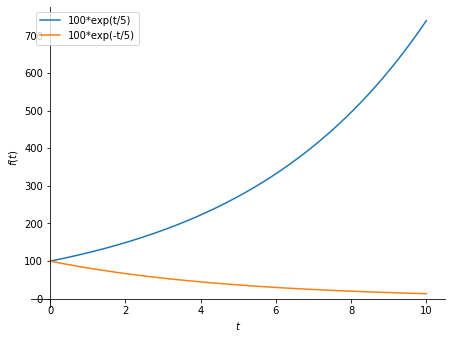

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(100 * exp(Rational(1, 5) * t), 100 * exp(-Rational(1, 5) * t), (t, 0, 10), legend=True);
```

</details>

#### Aufgabe 1.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
f = 50 * exp(log(2) * t)
display(f.subs(t, 0))
display(f.subs(t, 1))
display(f.subs(t, 3))
simplify(f)
```

In [ ]:
f = 50 * exp(log(2) * t)
display(f.subs(t, 0))
display(f.subs(t, 1))
display(f.subs(t, 3))
simplify(f)

## 2. Parameter aus Messwerten

#### Zwei Messwerte bestimmen das Modell

Für f(t) = c · e^(kt) braucht man zwei Messwerte. Aus f(0) = c folgt c direkt; aus einem zweiten Wert f(t₁) = y₁ folgt k.
Sind beide Werte nicht bei t = 0, teilt man die Gleichungen: f(t₂)/f(t₁) = e^(k(t₂ − t₁)).

Beispiel: Eine Bakterienkultur hat am Anfang 50 und nach 5 Stunden 80 Bakterien.

In [ ]:
l = solveset(Eq(50 * exp(5*k), 80), k, S.Reals)
k0 = list(l)[0]
display(k0, N(k0, 4))
f = 50 * exp(k0 * t)
display(f)
N(f.subs(t, 12), 4)

#### Aufgabe 2.1

Ein Bestand hat am Anfang 1200 und nach 3 Tagen 1500 Einheiten (exponentielles Wachstum). Bestimme k genau und mit 4 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle \frac{\log{\left(\frac{5}{4} \right)}}{3}$

$\displaystyle 0.07438$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k0 = list(solveset(Eq(1200 * exp(3*k), 1500), k, S.Reals))[0]
display(k0)
N(k0, 4)
```

</details>

#### Aufgabe 2.2

Mit welchem Bestand ist im Modell der vorigen Aufgabe nach 10 Tagen zu rechnen? (auf eine ganze Zahl gerundet)

**Erwartete Ausgabe:**

$\displaystyle 2525$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k0 = log(Rational(5, 4)) / 3
round(N(1200 * exp(k0 * 10)))
```

</details>

#### Aufgabe 2.3

Eine Tasse Kaffee enthält 100 mg Koffein, nach 2 Stunden sind es noch 76 mg. Bestimme k (4 Ziffern) und die Halbwertszeit (4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle -0.1372$

$\displaystyle 5.051$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k0 = list(solveset(Eq(100 * exp(2*k), 76), k, S.Reals))[0]
display(N(k0, 4))
N(log(2) / Abs(k0), 4)
```

</details>

#### Aufgabe 2.4

Ein Bestand wird nach 2 Stunden mit 300 und nach 6 Stunden mit 1200 gemessen. Bestimme k (aus 1200/300 = e^(4k)) und dann c aus c · e^(2k) = 300.

**Erwartete Ausgabe:**

$\displaystyle \frac{\log{\left(4 \right)}}{4}$

$\displaystyle \left[ 150\right]$

In [ ]:
c = symbols('c', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
c = symbols('c', positive=True)
k0 = list(solveset(Eq(exp(4*k), 4), k, S.Reals))[0]
display(k0)
solve(Eq(c * exp(2*k0), 300), c)
```

</details>

#### Aufgabe 2.5

Löse dieselbe Aufgabe mit einem Gleichungssystem: `solve([Eq(c*exp(2*k), 300), Eq(c*exp(6*k), 1200)], [c, k], dict=True)` (c positiv angelegt).

**Erwartete Ausgabe:**

$\displaystyle \left[ \left\{ c : 150, \  k : \frac{\log{\left(2 \right)}}{2}\right\}\right]$

In [ ]:
c = symbols('c', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
c = symbols('c', positive=True)
solve([Eq(c * exp(2*k), 300), Eq(c * exp(6*k), 1200)], [c, k], dict=True)
```

</details>

#### Aufgabe 2.6

**Weltbevölkerung:** 1990 lebten etwa 5,3 Mrd., 2020 etwa 7,8 Mrd. Menschen. Bestimme ein exponentielles Modell (t in Jahren ab 1990) und die Prognose
für 2050 mit 3 Ziffern.

**Erwartete Ausgabe:**

$\displaystyle 11.5$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k0 = list(solveset(Eq(Rational(53, 10) * exp(30*k), Rational(78, 10)), k, S.Reals))[0]
f = Rational(53, 10) * exp(k0 * t)
N(f.subs(t, 60), 3)
```

</details>

## 3. Beschränktes Wachstum

#### f(t) = S − (S − f(0)) · e^(−kt)

Bei **beschränktem Wachstum** nähert sich der Bestand einer **Schranke** S. Die Änderungsrate ist proportional zum **Sättigungsmanko** S − f(t):
je näher am Ziel, desto langsamer. Beispiele: Abkühlung (S = Raumtemperatur), Lernkurven, Erwärmung, Medikamente bei Dauerinfusion.

f(t) = S − (S − f(0)) · e^(−kt) mit k > 0. Für t → ∞ geht f(t) → S.

In [ ]:
f = 20 + (90 - 20) * exp(-Rational(1, 10) * t)
display(f)
display(N(f.subs(t, 10), 4))
display(limit(f, t, oo))
plot(f, 20, (t, 0, 40), ylim=(0, 100));

#### Aufgabe 3.1

**Abkühlung:** Ein Tee hat 85 °C, der Raum 22 °C, k = 0,05 (pro Minute). Gib das Modell aus und die Temperatur nach 15 Minuten (4 Ziffern).

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle 22 + 63 e^{- \frac{t}{20}}$

$\displaystyle 51.76$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = 22 + (85 - 22) * exp(-Rational(1, 20) * t)
display(f)
N(f.subs(t, 15), 4)
```

</details>

#### Aufgabe 3.2

Wann ist der Tee aus der vorigen Aufgabe auf 50 °C abgekühlt? Genau und mit 4 Ziffern.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \left\{- 20 \log{\left(\frac{4}{9} \right)}\right\}$

$\displaystyle 16.22$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = 22 + (85 - 22) * exp(-Rational(1, 20) * t)
l = solveset(Eq(f, 50), t, S.Reals)
display(l)
N(list(l)[0], 4)
```

</details>

#### Aufgabe 3.3

**Erwärmung:** Eine Flasche hat 6 °C und kommt in einen 24 °C warmen Raum. Nach 20 Minuten hat sie 12 °C. Bestimme k (genau und 4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle - \frac{\log{\left(\frac{2}{3} \right)}}{20}$

$\displaystyle 0.02027$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = 24 - (24 - 6) * exp(-k * t)
k0 = list(solveset(Eq(f.subs(t, 20), 12), k, S.Reals))[0]
display(k0)
N(k0, 4)
```

</details>

#### Aufgabe 3.4

**Lernkurve:** Jemand lernt Vokabeln. Höchstens 200 Wörter kann er sich merken, am Anfang kennt er 0, nach 5 Tagen 80. Bestimme das Modell f(t) = 200 − 200 · e^(−kt)
und wann er 180 Wörter kennt (4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 200 - 200 e^{\frac{t \log{\left(\frac{3}{5} \right)}}{5}}$

$\displaystyle 22.54$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k0 = list(solveset(Eq(200 - 200 * exp(-5*k), 80), k, S.Reals))[0]
f = 200 - 200 * exp(-k0 * t)
display(f)
N(list(solveset(Eq(f, 180), t, S.Reals))[0], 4)
```

</details>

#### Aufgabe 3.5

Prüfe für f(t) = 20 + 70 · e^(−0,1t), dass die Änderungsrate proportional zum Abstand von S = 20 ist: `simplify(f' − (−0,1) · (f − 20))` muss 0 sein.

**Erwartete Ausgabe:**

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = 20 + 70 * exp(-Rational(1, 10) * t)
simplify(diff(f, t) - (-Rational(1, 10)) * (f - 20))
```

</details>

#### Aufgabe 3.6

Zeichne die beschränkten Wachstumskurven f(t) = 100 − 100 · e^(−kt) für k = 0,1, 0,3 und 1 in ein Diagramm (0 ≤ t ≤ 20, mit Legende).

**Erwartete Ausgabe:**



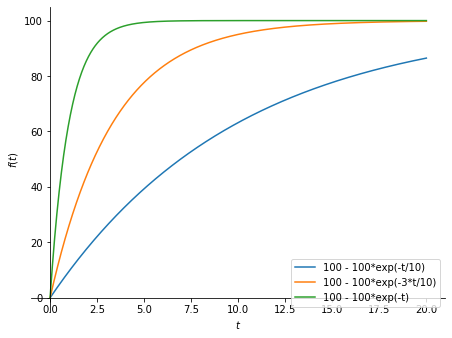

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(*[100 - 100 * exp(-w * t) for w in [Rational(1, 10), Rational(3, 10), 1]], (t, 0, 20), legend=True);
```

</details>

#### Aufgabe 3.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
f = 50 - 30 * exp(-t)
display(f.subs(t, 0))
display(limit(f, t, oo))
diff(f, t).subs(t, 0)
```

In [ ]:
f = 50 - 30 * exp(-t)
display(f.subs(t, 0))
display(limit(f, t, oo))
diff(f, t).subs(t, 0)

## 4. Bestand und Änderungsrate

#### Wachstumsgeschwindigkeit

Die **Änderungsrate** f'(t) gibt an, wie schnell der Bestand gerade wächst.
- Exponentiell: f'(t) = k · f(t) (die Rate ist proportional zum **Bestand**)
- Beschränkt: f'(t) = k · (S − f(t)) (die Rate ist proportional zum **Sättigungsmanko**)

Mit der Integralrechnung bekommt man umgekehrt aus der Änderungsrate die Änderung des Bestands.

In [ ]:
f = 400 * exp(Rational(1, 5) * t)
display(diff(f, t))
display(simplify(diff(f, t) - Rational(1, 5) * f))
display(N(diff(f, t).subs(t, 5), 4))
integrate(diff(f, t), (t, 0, 5)) == f.subs(t, 5) - f.subs(t, 0)

#### Aufgabe 4.1

Ein Bestand wächst nach f(t) = 800 · e^(0,04t). Wie groß ist die Wachstumsgeschwindigkeit zu Beginn und nach 10 Zeiteinheiten (4 Ziffern)?

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle 32$

$\displaystyle 47.74$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = 800 * exp(Rational(4, 100) * t)
display(diff(f, t).subs(t, 0))
N(diff(f, t).subs(t, 10), 4)
```

</details>

#### Aufgabe 4.2

Wann wächst der Bestand aus der vorigen Aufgabe mit 50 Einheiten pro Zeiteinheit? (4 Ziffern)

**Erwartete Ausgabe:**

$\displaystyle 11.16$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = 800 * exp(Rational(4, 100) * t)
N(list(solveset(Eq(diff(f, t), 50), t, S.Reals))[0], 4)
```

</details>

#### Aufgabe 4.3

Eine Tablette löst sich mit der Rate r(t) = 20 · e^(−0,5t) mg pro Minute auf. Wie viel mg lösen sich in den ersten 4 Minuten (4 Ziffern), wie viel insgesamt?

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle 34.59$

$\displaystyle 40$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
r = 20 * exp(-Rational(1, 2) * t)
display(N(integrate(r, (t, 0, 4)), 4))
integrate(r, (t, 0, oo))
```

</details>

#### Aufgabe 4.4

Prüfe: Für welches k erfüllt f(t) = 3 · e^(kt) die Gleichung f'(t) = −0,25 · f(t)? Löse `Eq(diff(f, t), -Rational(1, 4) * f)` nach k.

**Erwartete Ausgabe:**

$\displaystyle \left[ - \frac{1}{4}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = 3 * exp(k * t)
solve(Eq(diff(f, t), -Rational(1, 4) * f), k)
```

</details>

#### Aufgabe 4.5

Ein beschränktes Wachstum hat die Schranke 500 und f(0) = 100, k = 0,2. Gib die Änderungsrate zu Beginn und zum Zeitpunkt, an dem f = 400 ist, aus (über f' = k(S − f)).

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle 80$

$\displaystyle 20$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
kk = Rational(1, 5)
display(kk * (500 - 100))
kk * (500 - 400)
```

</details>

## 5. Differentialgleichungen (Leistungsfach)

#### `dsolve()`

Eine **Differentialgleichung** ist eine Gleichung, in der eine Funktion und ihre Ableitung vorkommen, z. B. f'(t) = 0,3 · f(t).
Gesucht ist **die Funktion** f. In sympy legst du dafür ein Funktionssymbol mit `Function('f')` an; f(t) ist dann die
unbekannte Funktion und `f(t).diff(t)` ihre Ableitung.

- `dsolve(gleichung, f(t))` liefert die **allgemeine Lösung** mit einer Konstanten C1.
- Mit `ics={f(0): 100}` (Anfangswert) wird die Konstante bestimmt.
- `.rhs` (right hand side) ist die rechte Seite der Lösung, also der Funktionsterm.
- `checkodesol(gleichung, loesung)` prüft die Lösung: `(True, 0)` bedeutet richtig.

In [ ]:
f = Function('f')
dgl = Eq(f(t).diff(t), Rational(3, 10) * f(t))
display(dgl)
display(dsolve(dgl, f(t)))
loesung = dsolve(dgl, f(t), ics={f(0): 100})
display(loesung)
display(loesung.rhs.subs(t, 2))
checkodesol(dgl, loesung)

#### Aufgabe 5.1

Löse die Differentialgleichung f'(t) = −0,5 · f(t) allgemein.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle f{\left(t \right)} = C_{1} e^{- \frac{t}{2}}$

In [ ]:
f = Function('f')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = Function('f')
dsolve(Eq(f(t).diff(t), -Rational(1, 2) * f(t)), f(t))
```

</details>

#### Aufgabe 5.2

Löse f'(t) = −0,5 · f(t) mit dem Anfangswert f(0) = 80.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle f{\left(t \right)} = 80 e^{- \frac{t}{2}}$

In [ ]:
f = Function('f')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = Function('f')
dsolve(Eq(f(t).diff(t), -Rational(1, 2) * f(t)), f(t), ics={f(0): 80})
```

</details>

#### Aufgabe 5.3

Löse die Differentialgleichung des beschränkten Wachstums f'(t) = 0,1 · (50 − f(t)) mit f(0) = 10.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle f{\left(t \right)} = 50 - 40 e^{- \frac{t}{10}}$

In [ ]:
f = Function('f')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = Function('f')
dsolve(Eq(f(t).diff(t), Rational(1, 10) * (50 - f(t))), f(t), ics={f(0): 10})
```

</details>

#### Aufgabe 5.4

Löse f'(t) = k · (G − f(t)) mit f(0) = 0 allgemein (k und die Schranke G positiv anlegen).

**Erwartete Ausgabe:**

$\displaystyle f{\left(t \right)} = G - G e^{- k t}$

In [ ]:
f = Function('f')
k, G = symbols('k G', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = Function('f')
k, G = symbols('k G', positive=True)
dsolve(Eq(f(t).diff(t), k * (G - f(t))), f(t), ics={f(0): 0})
```

</details>

#### Aufgabe 5.5

Prüfe mit `checkodesol`, ob f(t) = 50 − 40 · e^(−t/10) die Differentialgleichung f'(t) = 0,1 · (50 − f(t)) löst.

**Erwartete Ausgabe:**

```
(True, 0)
```

In [ ]:
f = Function('f')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = Function('f')
dgl = Eq(f(t).diff(t), Rational(1, 10) * (50 - f(t)))
checkodesol(dgl, Eq(f(t), 50 - 40 * exp(-t / 10)))
```

</details>

#### Aufgabe 5.6

Prüfe genauso, ob f(t) = 50 + 40 · e^(−t/10) eine Lösung ist, und ob f(t) = 50 − 40 · e^(t/10) eine ist (zwei Ausgaben).

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

```
(True, 0)
```

```
(False, -8*exp(t/10))
```

In [ ]:
f = Function('f')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = Function('f')
dgl = Eq(f(t).diff(t), Rational(1, 10) * (50 - f(t)))
display(checkodesol(dgl, Eq(f(t), 50 + 40 * exp(-t / 10))))
checkodesol(dgl, Eq(f(t), 50 - 40 * exp(t / 10)))
```

</details>

#### Aufgabe 5.7

**Abkühlung:** Eine Suppe mit 90 °C kühlt in einem 20 °C warmen Raum nach T'(t) = −0,08 · (T(t) − 20) ab. Löse die Differentialgleichung und gib die Temperatur
nach 10 Minuten mit 4 Ziffern aus.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle T{\left(t \right)} = 20 + 70 e^{- \frac{2 t}{25}}$

$\displaystyle 51.45$

In [ ]:
T = Function('T')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
T = Function('T')
l = dsolve(Eq(T(t).diff(t), -Rational(8, 100) * (T(t) - 20)), T(t), ics={T(0): 90})
display(l)
N(l.rhs.subs(t, 10), 4)
```

</details>

#### Aufgabe 5.8

**Zufluss:** In einen Teich fließen pro Tag 100 m³ Wasser, gleichzeitig verdunsten 2 % des Wasservolumens V pro Tag: V'(t) = 100 − 0,02 · V(t), V(0) = 1000.
Löse die Differentialgleichung und gib den Grenzwert für t → ∞ aus.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle V{\left(t \right)} = 5000 - 4000 e^{- \frac{t}{50}}$

$\displaystyle 5000$

In [ ]:
V = Function('V')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
V = Function('V')
l = dsolve(Eq(V(t).diff(t), 100 - Rational(2, 100) * V(t)), V(t), ics={V(0): 1000})
display(l)
limit(l.rhs, t, oo)
```

</details>

## 6. Logistisches Wachstum (Zusatz)

#### f(t) = S / (1 + a · e^(−k·S·t))

Beim **logistischen Wachstum** ist die Änderungsrate proportional zum Bestand **und** zum Sättigungsmanko: f'(t) = k · f(t) · (S − f(t)).
Am Anfang wächst der Bestand fast exponentiell, später fast beschränkt. Am **Wendepunkt** (bei f = S/2) ist das Wachstum am schnellsten.

Eine Lösung ist f(t) = S / (1 + a · e^(−k·S·t)) mit a = S/f(0) − 1.

In [ ]:
G, a = 1000, 99
kk = Rational(1, 5000)
f = G / (1 + a * exp(-kk * G * t))
display(f, f.subs(t, 0))
display(simplify(diff(f, t) - kk * f * (G - f)))
tw = solve(diff(f, t, 2), t)[0]
display(tw, N(tw, 4), f.subs(t, tw))
plot(f, (t, 0, 50));

#### Aufgabe 6.1

Eine Grippe breitet sich in einer Schule mit 800 Schülern logistisch aus: f(t) = 800 / (1 + 79 · e^(−0,4t)) (t in Tagen). Wie viele sind am Anfang krank, wie viele
nach 10 Tagen (gerundet)?

**Erwartete Ausgabe:**

$\displaystyle 10$

$\displaystyle 327$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = 800 / (1 + 79 * exp(-Rational(2, 5) * t))
display(f.subs(t, 0))
round(N(f.subs(t, 10)))
```

</details>

#### Aufgabe 6.2

Wann breitet sich die Grippe aus der vorigen Aufgabe am schnellsten aus (Wendestelle, genau und mit 4 Ziffern)? Wie viele sind dann krank?

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle 5 \log{\left(\sqrt{79} \right)}$

$\displaystyle 10.92$

$\displaystyle 400$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = 800 / (1 + 79 * exp(-Rational(2, 5) * t))
tw = solve(diff(f, t, 2), t)[0]
display(tw, N(tw, 4))
f.subs(t, tw)
```

</details>

#### Aufgabe 6.3

Prüfe, dass f(t) = 800 / (1 + 79 · e^(−0,4t)) die Gleichung f'(t) = 0,0005 · f(t) · (800 − f(t)) erfüllt (Differenz mit `simplify`).

**Erwartete Ausgabe:**

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = 800 / (1 + 79 * exp(-Rational(2, 5) * t))
simplify(diff(f, t) - Rational(5, 10000) * f * (800 - f))
```

</details>

#### Aufgabe 6.4

Zeichne die logistische Kurve der Grippe-Aufgabe und ihre Ableitung (Ausbreitungsgeschwindigkeit) für 0 ≤ t ≤ 25 in zwei Diagramme.

**Erwartete Ausgabe:**



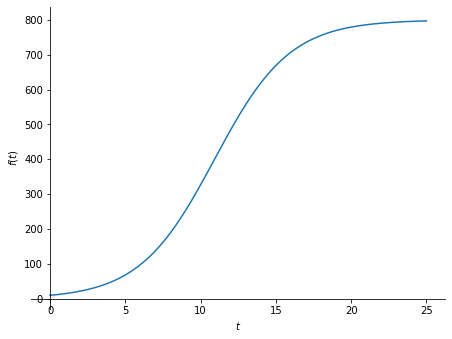

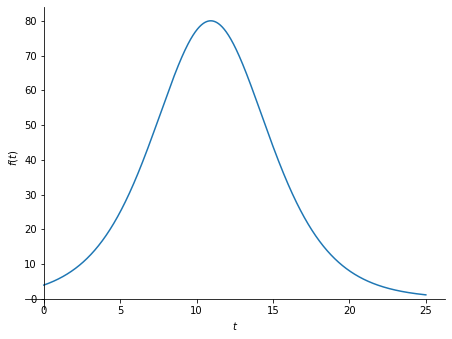

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = 800 / (1 + 79 * exp(-Rational(2, 5) * t))
plot(f, (t, 0, 25));
plot(diff(f, t), (t, 0, 25));
```

</details>

## 7. Gemischte Übungen

#### Aufgabe 7.1

Ein radioaktives Präparat hat eine Halbwertszeit von 8 Tagen. Wie viel Prozent sind nach 30 Tagen noch vorhanden (3 Ziffern)?

**Erwartete Ausgabe:**

$\displaystyle 7.43$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
N(100 * Rational(1, 2)**Rational(30, 8), 3)
```

</details>

#### Aufgabe 7.2

Ein Auto verliert pro Jahr 15 % an Wert, Neupreis 30 000 €. Nach wie vielen Jahren ist es weniger als 10 000 € wert? Gib die genaue Lösung mit 4 Ziffern
und die nächste ganze Zahl (`ceiling`) aus.

**Erwartete Ausgabe:**

$\displaystyle 6.76$

$\displaystyle 7$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = solveset(Eq(30000 * Rational(85, 100)**t, 10000), t, S.Reals)
w = list(l)[0]
display(N(w, 4))
ceiling(w)
```

</details>

#### Aufgabe 7.3

Ein Ball wird aus dem Kühlschrank (4 °C) in einen 20 °C warmen Raum gelegt. Nach 10 Minuten hat er 10 °C. Wann hat er 18 °C? (beschränktes Wachstum, 4 Ziffern)

**Erwartete Ausgabe:**

$\displaystyle 44.24$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = 20 - 16 * exp(-k * t)
k0 = list(solveset(Eq(f.subs(t, 10), 10), k, S.Reals))[0]
N(list(solveset(Eq(f.subs(k, k0), 18), t, S.Reals))[0], 4)
```

</details>

#### Aufgabe 7.4

Vergleiche zwei Angebote: A wächst exponentiell mit f(t) = 1000 · e^(0,05t), B linear mit g(t) = 1000 + 80t. Ab wann ist A größer? (`nsolve` mit Startwert 20, 4 Ziffern)

**Erwartete Ausgabe:**

$\displaystyle 17.53$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
N(nsolve(1000 * exp(Rational(5, 100) * t) - (1000 + 80*t), t, 20), 4)
```

</details>

#### Aufgabe 7.5

Zeichne die beiden Angebote aus der vorigen Aufgabe für 0 ≤ t ≤ 30 (mit Legende).

**Erwartete Ausgabe:**



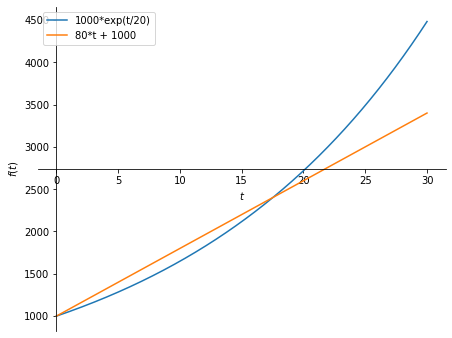

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
plot(1000 * exp(Rational(5, 100) * t), 1000 + 80*t, (t, 0, 30), legend=True);
```

</details>